# HW2. Стекинг


In [ ]:
import operator
import subprocess
import sys
import time
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from joblib import Parallel, delayed
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier, StackingClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer
from sklearn.metrics import f1_score

import solution_utils as su
from solution_utils import CLASSES, NUMERIC_COLUMNS, SEED

## 1. Данные и разбиение


In [2]:
task1 = su.load_task1(su.train_path(), su.flags_path())
train_df, test_df = su.split_task1(task1)

train_dialogs = train_df[["dialog_id", "turns"]].to_dict("records")
test_dialogs = test_df[["dialog_id", "turns"]].to_dict("records")
y_train, y_test = train_df["reaction"].to_numpy(), test_df["reaction"].to_numpy()

folds = su.get_folds(y_train, train_df["group_id"].to_numpy())      # одни блоки для всех моделей
all_blocks = [val for _, val in folds]                              # индексы проверочных блоков
n_folds = len(folds)

print(f"train: {len(train_df)} | test: {len(test_df)} | блоков: {n_folds}, размеры: {[len(b) for b in all_blocks]}")

train: 2344 | test: 586 | блоков: 5, размеры: [469, 468, 471, 468, 468]


## 2. Вход стекинга: таблица `make_frame`

In [4]:
dialog_flags = su.load_flags()
X_train, X_test = su.make_frame(train_dialogs, dialog_flags), su.make_frame(test_dialogs, dialog_flags)
X_train

,dialog_id,user_text,last_user,dialog_text,n_user_turns_declared,n_user_actual,n_messages,n_label_turns,n_chars_total,max_msg_chars,...,has_code,has_user_code,has_assistant_code,has_assistant_loop,user_has_cyrillic,has_empty_message,has_short_turn,is_template,is_exact_dup,in_near_dup_group
0,d094012177e,"it’s like: 1+1=2, but 1+1=2+1+1=? is undefined...","any spec symbols used in ""paradoxical arithmet...","it’s like: 1+1=2, but 1+1=2+1+1=? is undefined...",7,7,14,7,18945,7924,...,False,False,False,False,False,False,False,False,False,False
1,d306fbe61fe,Can you help me train a small language model t...,Give me GUI for this portion,Can you help me train a small language model t...,8,8,16,8,33533,5558,...,True,False,True,False,False,False,False,False,False,False
2,dd6905952c7,ask questions about a fictional voice actor i ...,1.Alex was at the supermarket when a fan bumpe...,ask questions about a fictional voice actor i ...,5,5,10,5,15264,3789,...,False,False,False,False,False,False,False,False,False,False
3,d767a675896,Calculate each prompt based off of data and sh...,recalculate everything considering the porport...,Calculate each prompt based off of data and sh...,6,6,12,6,10368,1984,...,False,False,False,False,False,False,False,False,False,False
4,d7a6280ce8e,"mass spectrometer, the length of AC rod will i...",how many masses we have on spectrometer,"mass spectrometer, the length of AC rod will i...",8,8,16,8,7902,1519,...,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2339,d43fdacfdf2,talking points for meeting between Prime Minis...,Amer International Group Ltd is a high-tech in...,talking points for meeting between Prime Minis...,6,6,12,6,15768,3181,...,False,False,False,False,False,False,False,False,False,False
2340,ddf17ced020,И здесь К-ый максимум...\nБабушка Дуся вернула...,"При чем тут поле имён, у тебя код не работает,...",И здесь К-ый максимум...\nБабушка Дуся вернула...,8,8,16,8,12854,1852,...,True,False,True,False,True,False,False,False,False,False
2341,d1f0a4cb059,What languages do you understand I have found ...,Make a conclusion basing on the previous message,What languages do you understand As an AI lang...,5,5,10,5,6255,1860,...,False,False,False,False,True,False,False,False,False,False
2342,dc047dadf97,Фрукты\nПользователь вводит число K - количест...,Таблицей умножения назовем таблицу размера n с...,Фрукты\nПользователь вводит число K - количест...,5,5,10,5,7409,1305,...,True,True,True,False,True,False,False,False,False,False


## 3. Базовые модели

Все базовые модели принимают **таблицу** `make_frame`.

Старые модели HW1 оборачиваются в пайплайн, чтобы обучаться на `dialog_text` (`itemgetter`, а не лямбда, т.к. лямбду нельзя сохранить в `joblib`);

`DummyClassifier`-ы из HW1 (`most_frequent`, `stratified`) базовыми не берём, так как они совсем глупые

`Pavel_Dimon_ARTIFACTS` (имена файлов из `artifacts/` без `.joblib`).
Модель клонируется с её гиперпараметрами и переобучается внутри стекинга; на вход ей должна идти таблица `make_frame`.

In [5]:
Pavel_Dimon_ARTIFACTS = ["hw2_random_forest", "hw2_gb_sklearn"]

old_models = su.load_models("hw1_")
OLD_NAMES = ["hw1_bow_logreg", "hw1_tfidf_logreg", "hw1_kirp_model"]

for need in OLD_NAMES:
    assert need in old_models, f"нет {need}.joblib в artifacts/: выполните подготовку (перенос моделей HW1)"

def wrap_old(model):
    # таблица -> столбец dialog_text -> старая модель HW1
    return Pipeline([("text", FunctionTransformer(operator.itemgetter("dialog_text"))),
                     ("old", clone(model))])


BASES = {
    "hw1_bow_logreg": wrap_old(old_models["hw1_bow_logreg"]),
    "hw1_tfidf_logreg": wrap_old(old_models["hw1_tfidf_logreg"]),
    "hw1_kirp_model": wrap_old(old_models["hw1_kirp_model"]),
}
if Pavel_Dimon_ARTIFACTS:
    hw2_models = su.load_models("hw2_")
    for name in Pavel_Dimon_ARTIFACTS:
        BASES[name] = clone(hw2_models[name])

list(BASES)

['hw1_bow_logreg',
 'hw1_tfidf_logreg',
 'hw1_kirp_model',
 'hw2_random_forest',
 'hw2_gb_sklearn']

## 4. Предсказания вне блоков и вложенная схема без утечки

Блоки кросс-валидации: $B_0,\dots,B_4$. Для каждой базовой модели считаем:

- `oof[name]` — вероятности для блока $B_k$ от модели, обученной на остальных четырёх блоках («внешние» предсказания);
- `inner[(name, k, j)]` — вероятности для блока $B_j$ от модели, обученной на блоках **без $B_k$ и без $B_j$**.

Тогда оценка стекинга для внешнего блока $B_k$ устроена так: метамодель учится на `inner[(·, k, j)]`, $j\ne k$, — там базовые модели не видели ни метки блока $j$, ни метки блока $k$ — и применяется к `oof[·][B_k]`.

Метки блока $B_k$ нигде не участвуют в обучении ни базовых моделей, ни метамодели.

Если же учить метамодель просто на `oof` оставшихся блоков, то эти предсказания получены моделями, **видевшими** $B_k$: это мягкая утечка, и оценка стекинга получается завышенной. Дальше в разделе 5 сравним оба варианта.

Всё это — 5 + 20 обучений каждой модели.

In [6]:
def blocks_except(*excluded):
    return np.concatenate([b for i, b in enumerate(all_blocks) if i not in excluded])


def fit_predict(estimator, train_idx, test_idx):
    model = clone(estimator).fit(X_train.iloc[train_idx], y_train[train_idx])
    assert list(model.classes_) == CLASSES
    return model.predict_proba(X_train.iloc[test_idx])


tasks = []                                       # (имя, внешний блок k, блок j с предсказаниями)
for name in BASES:
    for k in range(n_folds):
        tasks.append((name, k, k))               # внешнее предсказание
        tasks += [(name, k, j) for j in range(n_folds) if j != k]    # внутренние

t0 = time.perf_counter()
preds = Parallel(n_jobs=4)(
    delayed(fit_predict)(BASES[name], blocks_except(k, j), all_blocks[j]) for name, k, j in tasks)
print(tasks)
print(f"обучено {len(tasks)} раз за {time.perf_counter() - t0:.0f} с")

oof = {name: np.zeros((len(y_train), len(CLASSES))) for name in BASES}
inner = {}
for (name, k, j), proba in zip(tasks, preds):
    if k == j:
        oof[name][all_blocks[k]] = proba
    else:
        inner[(name, k, j)] = proba

[('hw1_bow_logreg', 0, 0), ('hw1_bow_logreg', 0, 1), ('hw1_bow_logreg', 0, 2), ('hw1_bow_logreg', 0, 3), ('hw1_bow_logreg', 0, 4), ('hw1_bow_logreg', 1, 1), ('hw1_bow_logreg', 1, 0), ('hw1_bow_logreg', 1, 2), ('hw1_bow_logreg', 1, 3), ('hw1_bow_logreg', 1, 4), ('hw1_bow_logreg', 2, 2), ('hw1_bow_logreg', 2, 0), ('hw1_bow_logreg', 2, 1), ('hw1_bow_logreg', 2, 3), ('hw1_bow_logreg', 2, 4), ('hw1_bow_logreg', 3, 3), ('hw1_bow_logreg', 3, 0), ('hw1_bow_logreg', 3, 1), ('hw1_bow_logreg', 3, 2), ('hw1_bow_logreg', 3, 4), ('hw1_bow_logreg', 4, 4), ('hw1_bow_logreg', 4, 0), ('hw1_bow_logreg', 4, 1), ('hw1_bow_logreg', 4, 2), ('hw1_bow_logreg', 4, 3), ('hw1_tfidf_logreg', 0, 0), ('hw1_tfidf_logreg', 0, 1), ('hw1_tfidf_logreg', 0, 2), ('hw1_tfidf_logreg', 0, 3), ('hw1_tfidf_logreg', 0, 4), ('hw1_tfidf_logreg', 1, 1), ('hw1_tfidf_logreg', 1, 0), ('hw1_tfidf_logreg', 1, 2), ('hw1_tfidf_logreg', 1, 3), ('hw1_tfidf_logreg', 1, 4), ('hw1_tfidf_logreg', 2, 2), ('hw1_tfidf_logreg', 2, 0), ('hw1_tfidf_l

In [9]:
cv_table = pd.read_csv(su.RESULTS / "cv_table.csv", index_col=0)
old_rows = cv_table[cv_table.index.str.startswith("hw1_")]
assert len(old_rows), "в results/cv_table.csv нет строк hw1_: выполните подготовку"
best_old_name, best_old_f1 = old_rows["macro_f1"].idxmax(), old_rows["macro_f1"].max()

base_table = pd.DataFrame({name: su.all_metrics(y_train, oof[name]) for name in BASES}).T
base_table.sort_values("macro_f1", ascending=False)[["macro_f1", "accuracy", "balanced_accuracy", "roc_auc_macro"]].round(3)

,macro_f1,accuracy,balanced_accuracy,roc_auc_macro
hw2_random_forest,0.613,0.679,0.603,0.783
hw1_tfidf_logreg,0.583,0.704,0.560,0.783
hw1_kirp_model,0.564,0.701,0.542,0.777
hw2_gb_sklearn,0.554,0.657,0.545,0.750
hw1_bow_logreg,0.529,0.659,0.516,0.705


In [10]:
print(f"лучшая старая модель на CV: {best_old_name}, macro-F1 = {best_old_f1:.3f}")

лучшая старая модель на CV: hw1_tfidf_logreg, macro-F1 = 0.583


## 5. Подбор: блендинг и стекинг

Перебрал все возможные сочетания базовых моделей. В качестве объединения использовал среднее вероятностей, т.е. блэндинг, а также три метамодели: логистическая регрессия с разной силой регуляризации `C` и с весами классов / без них, и (для контраста) маленький бустинг


In [11]:
def meta_cv(names, meta, nested=True):
    # Предсказания метамодели на каждом блоке. nested=True — без утечки, nested=False — «наивно» (для сравнения).
    out = np.zeros((len(y_train), len(CLASSES)))
    for k, val in enumerate(all_blocks):
        if nested:
            others = [j for j in range(n_folds) if j != k]
            Z_tr = np.vstack([np.hstack([inner[(n, k, j)] for n in names]) for j in others])
            y_tr = np.concatenate([y_train[all_blocks[j]] for j in others])
        else:
            train_idx = folds[k][0]
            Z_tr, y_tr = np.hstack([oof[n][train_idx] for n in names]), y_train[train_idx]
        Z_val = np.hstack([oof[n][val] for n in names])
        out[val] = clone(meta).fit(Z_tr, y_tr).predict_proba(Z_val)
    return out


SUBSETS = {"old": OLD_NAMES, 
           "forest": ["hw2_random_forest"], 
           "boosting": ["hw2_gb_sklearn"],
           "old+forest": OLD_NAMES + ["hw2_random_forest"],
           "old+boosting": OLD_NAMES + ["hw2_gb_sklearn"],
           "forest+boosting": ["hw2_random_forest", "hw2_gb_sklearn"], 
           "old+forest+boosting": list(BASES),
           }
VALID_SUBSETS = [s for s, names in SUBSETS.items() if len(names) >= 3 and set(names) & set(OLD_NAMES)]

META_CANDIDATES = {}
for C in [0.03, 0.3, 3.0]:
    for cw in [None, "balanced"]:
        META_CANDIDATES[f"lr_C{C}_{cw or 'plain'}"] = LogisticRegression(C=C, class_weight=cw, max_iter=2000)
META_CANDIDATES["hgb_depth2"] = HistGradientBoostingClassifier(max_depth=2, max_iter=60, learning_rate=0.05,
                                                              random_state=SEED)

records = []
for label, names in SUBSETS.items():
    blend = np.mean([oof[n] for n in names], axis=0)
    records.append({"kind": "blend_mean", "subset": label, "meta": "-", **su.all_metrics(y_train, blend)})
    for meta_key, meta in META_CANDIDATES.items():
        records.append({"kind": "stacking", "subset": label, "meta": meta_key,
                        **su.all_metrics(y_train, meta_cv(names, meta))})

experiments = pd.DataFrame(records).sort_values("macro_f1", ascending=False).reset_index(drop=True)
experiments[["kind", "subset", "meta", "macro_f1", "accuracy", "balanced_accuracy"]].round(3)

,kind,subset,meta,macro_f1,accuracy,balanced_accuracy
0,stacking,old+forest+boosting,hgb_depth2,0.644,0.729,0.610
1,stacking,old+forest,hgb_depth2,0.639,0.725,0.605
2,stacking,old+forest+boosting,lr_C3.0_plain,0.629,0.718,0.601
3,stacking,old+forest,lr_C3.0_plain,0.627,0.718,0.597
4,stacking,old+forest,lr_C0.3_plain,0.620,0.718,0.587
5,stacking,old+forest+boosting,lr_C0.3_plain,0.619,0.719,0.587
6,blend_mean,forest,-,0.613,0.679,0.603
7,stacking,old+forest,lr_C0.03_balanced,0.609,0.677,0.637
8,stacking,forest+boosting,hgb_depth2,0.608,0.706,0.576
9,stacking,forest+boosting,lr_C3.0_plain,0.606,0.696,0.576


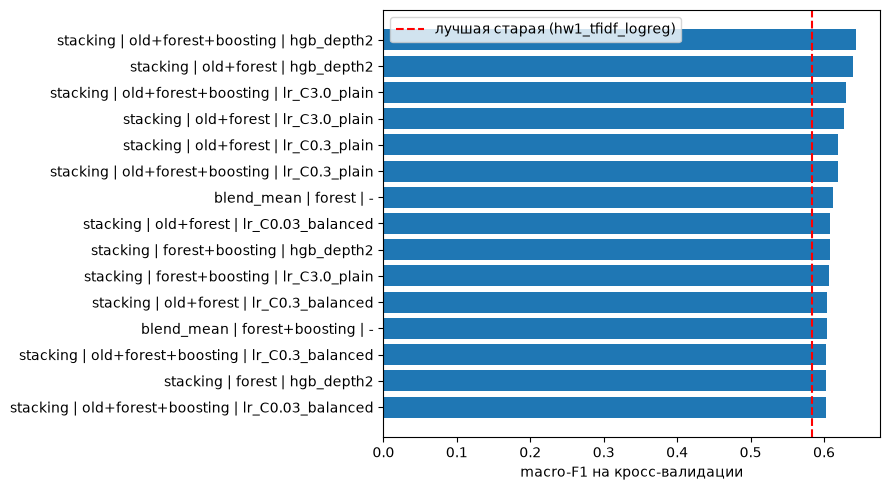

In [12]:
top = experiments.head(15).iloc[::-1]
plt.figure(figsize=(9, 5))
plt.barh(top["kind"] + " | " + top["subset"] + " | " + top["meta"], top["macro_f1"])
plt.axvline(best_old_f1, color="red", ls="--", label=f"лучшая старая ({best_old_name})")
plt.xlabel("macro-F1 на кросс-валидации"); plt.legend(); plt.tight_layout(); plt.show()

### Выбор конфигурации и проверка утечки

Лучшая конфигурация среди допустимых. Для неё же считаем «наивную» оценку (метамодель учится на `oof` оставшихся блоков, которые получены моделями, видевшими проверочный блок) и сравниваем с честной вложенной.

In [13]:
eligible = experiments[(experiments["kind"] == "stacking") & experiments["subset"].isin(VALID_SUBSETS)]
best = eligible.iloc[0]
best_names, best_meta = SUBSETS[best["subset"]], META_CANDIDATES[best["meta"]]
print(f"выбрано: базовые = {best_names}, метамодель = {best['meta']}")

cv_proba = meta_cv(best_names, best_meta)                          # честная вложенная оценка
cv_row = su.all_metrics(y_train, cv_proba)
naive_row = su.all_metrics(y_train, meta_cv(best_names, best_meta, nested=False))

leak = pd.DataFrame({"вложенно (без утечки)": cv_row, "наивно (с утечкой)": naive_row}).loc[
    ["macro_f1", "accuracy", "balanced_accuracy", "roc_auc_macro"]]
leak["разница"] = leak["наивно (с утечкой)"] - leak["вложенно (без утечки)"]
print(f"лучшая старая: {best_old_name}, macro-F1 = {best_old_f1:.3f} | стекинг: {cv_row['macro_f1']:.3f} "
      f"| выигрыш {cv_row['macro_f1'] - best_old_f1:+.3f}")
leak.round(4)

выбрано: базовые = ['hw1_bow_logreg', 'hw1_tfidf_logreg', 'hw1_kirp_model', 'hw2_random_forest', 'hw2_gb_sklearn'], метамодель = hgb_depth2
лучшая старая: hw1_tfidf_logreg, macro-F1 = 0.583 | стекинг: 0.644 | выигрыш +0.061


,вложенно (без утечки),наивно (с утечкой),разница
macro_f1,0.6440,0.6192,-0.0248
accuracy,0.7291,0.7163,-0.0128
balanced_accuracy,0.6099,0.5875,-0.0224
roc_auc_macro,0.8069,0.8077,0.0008


## 6. Финальная модель

Финальный стекинг — один sklearn-пайплайн, который целиком принимает таблицу `make_frame`:

- первый шаг называется **`features`** — по нему `su.uses_frame` понимает, что модели нужна таблица, а не список строк (шаг пропускает таблицу как есть);
- `StackingClassifier(cv=folds)` строит метапризнаки на **тех же блоках**, что и вся кросс-валидация, и затем переобучает базовые модели на всём train.

Никаких лямбд и классов из ноутбука: всё, что нужно для загрузки, есть в `sklearn` и `solution_utils` (токенайзер `smart_tokenizer`).

In [15]:
stack = Pipeline([
    ("features", FunctionTransformer()),
    ("stacking", StackingClassifier(
        estimators=[(name, clone(BASES[name])) for name in best_names],
        final_estimator=clone(best_meta),
        cv=folds,
        stack_method="predict_proba",
        passthrough=False,
        n_jobs=1,
    )),
])

t0 = time.perf_counter()
stack.fit(X_train, y_train)
print(f"обучено за {time.perf_counter() - t0:.0f} с; классы: {list(stack.classes_)}")
assert list(stack.classes_) == CLASSES

обучено за 749 с; классы: ['negative', 'neutral', 'positive']


### Веса метамодели: какие базовые модели и для каких классов она считает важными

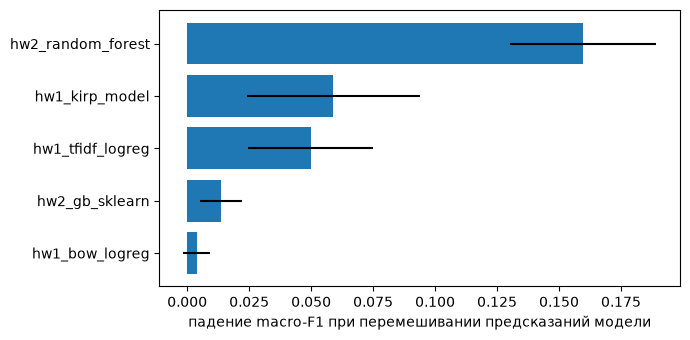

,падение macro-F1 (среднее),std
hw2_random_forest,0.1598,0.0295
hw1_kirp_model,0.0589,0.0350
hw1_tfidf_logreg,0.0497,0.0251
hw2_gb_sklearn,0.0136,0.0084
hw1_bow_logreg,0.0038,0.0055


In [32]:
def grouped_permutation_importance(names, meta, n_repeats=20, seed=SEED):
    # Падение macro-F1 метамодели на отложенном блоке, если столбцы одной базовой модели перемешать.
    # Три столбца модели (вероятности трёх классов) мешаем вместе, чтобы вектор вероятностей не рвался.
    rng = np.random.default_rng(seed)
    n_cls = len(CLASSES)
    drops = {n: [] for n in names}
    for k, val in enumerate(all_blocks):
        others = [j for j in range(n_folds) if j != k]
        Z_tr = np.vstack([np.hstack([inner[(n, k, j)] for n in names]) for j in others])
        y_tr = np.concatenate([y_train[all_blocks[j]] for j in others])
        Z_val = np.hstack([oof[n][val] for n in names])
        y_val = y_train[val]

        model = clone(meta).fit(Z_tr, y_tr)
        base = f1_score(y_val, model.predict(Z_val), labels=CLASSES, average="macro")
        for i, n in enumerate(names):
            cols = slice(i * n_cls, (i + 1) * n_cls)
            for _ in range(n_repeats):
                Z_perm = Z_val.copy()
                Z_perm[:, cols] = Z_val[rng.permutation(len(Z_val))][:, cols]
                score = f1_score(y_val, model.predict(Z_perm), labels=CLASSES, average="macro")
                drops[n].append(base - score)

    return pd.DataFrame({
        "падение macro-F1 (среднее)": {n: np.mean(v) for n, v in drops.items()},
        "std": {n: np.std(v) for n, v in drops.items()},
    }).sort_values("падение macro-F1 (среднее)", ascending=False)


meta_importance = grouped_permutation_importance(best_names, best_meta)

plt.figure(figsize=(7, 3.5))
plt.barh(meta_importance.index[::-1], meta_importance["падение macro-F1 (среднее)"][::-1],
         xerr=meta_importance["std"][::-1])
plt.xlabel("падение macro-F1 при перемешивании предсказаний модели")
plt.tight_layout(); plt.show()

meta_importance.round(4)

## 7. Сохранение и единственная оценка на тесте

Сохраняем модель, строку кросс-валидации (вложенная оценка выбранной конфигурации) и **единственный раз** считаем метрики на тесте.

In [18]:
su.save_model("hw2_stacking", stack)

experiments.assign(bases=experiments["subset"].map(lambda s: "+".join(SUBSETS[s]))).to_csv(
    su.RESULTS / "stacking_experiments.csv", index=False)
(su.RESULTS / "stacking_config.json").write_text(json.dumps({
    "base_models": best_names,
    "meta_model": best["meta"],
    "meta_params": best_meta.get_params(),
    "cv_macro_f1_nested": cv_row["macro_f1"],
    "cv_macro_f1_naive": naive_row["macro_f1"],
    "best_old": {"name": best_old_name, "cv_macro_f1": best_old_f1},
}, ensure_ascii=False, indent=2, default=str), encoding="utf-8")

su.save_result("cv_table.csv", "hw2_stacking", cv_row)

test_row = su.all_metrics(y_test, stack.predict_proba(X_test))
su.save_result("test_table.csv", "hw2_stacking", test_row)

cv_table = pd.read_csv(su.RESULTS / "cv_table.csv", index_col=0)
test_table = pd.read_csv(su.RESULTS / "test_table.csv", index_col=0)
cols = ["macro_f1", "accuracy", "balanced_accuracy"]
pd.concat({"cv": cv_table[cols], "test": test_table[cols]}, axis=1).round(3)

cv                                test           \
                  macro_f1 accuracy balanced_accuracy macro_f1 accuracy   
hw2_stacking         0.644    0.729             0.610    0.654    0.744   
hw1_tfidf_logreg     0.583    0.704             0.560    0.593    0.727   
hw1_kirp_model       0.564    0.701             0.542    0.581    0.724   
hw1_bow_logreg       0.529    0.656             0.516    0.495    0.655   
hw1_stratified       0.348    0.467             0.349    0.324    0.452   
hw1_most_frequent    0.248    0.593             0.333    0.252    0.606   

                                     
                  balanced_accuracy  
hw2_stacking                  0.617  
hw1_tfidf_logreg              0.559  
hw1_kirp_model                0.547  
hw1_bow_logreg                0.485  
hw1_stratified                0.324  
hw1_most_frequent             0.333

## 9. Что взять в отчёт

- Таблица `results/stacking_experiments.csv` и график из раздела 5 — путь подбора (какие составы и метамодели пробовали, что проиграло и почему).
- Сравнение «вложенно» и «наивно» из раздела 5 — иллюстрация утечки, о которой предупреждает задание.
- Веса метамодели из раздела 6 — какие базовые модели стекинг считает полезными.
- Выводы по полученным числам впишите сами:

*(вписать: выигрыш стекинга у лучшей старой модели на CV и на тесте; какие базовые модели вносят вклад; почему проиграли худшие конфигурации)*

В `solution.ipynb` ничего менять не нужно: `init_reaction_models` подхватывает все `artifacts/hw2_*.joblib`, а `su.make_input` по шагу `features` отдаёт стекингу таблицу `make_frame`.